In [ ]:
import sys
sys.path.append('../UniPert/perturbation_tasks/genetic_benchmark/GEARS-adapted')

from gears import PertData, GEARS

## load UniPert model

In [2]:
import sys
sys.path.append('../UniPert')

from unipert import UniPert

unipert_encoder = UniPert(
    data_dir='../UniPert/data', 
    model_hparams = {'save_dir': "../UniPert/current_model"}
    )

💡 Model have already trained at ../UniPert/current_model. 
💡 UniPert model hyperparameters settings:
    version: v1
    out_dim: 256
    gnn_type: GCN
    layer_num: 2
    graph_type: weighted_directed
    target_embedder: ESM2
    compound_embedder: ECFP4
    device: cuda:0
    exp_name: unipert_gnn_gs_0717/GCN_2_256
    seed: 2024
    bs: 512
    epochs1: 1000
    epochs2: 1000
    lr1: 0.005
    lr2: 0.005
    wd: 1e-05
    mm: 0.99
    drop_edge_p_1: 0.1
    drop_feat_p_1: 0.3
    drop_edge_p_2: 0.3
    drop_feat_p_2: 0.1
    exp_time: 20240717-113151
    save_dir: /fionafyang/lynnymli/UniPert/saved_models/unipert_gnn_gs_0717/GCN_2_256
Loading model from ../UniPert/current_model...
💡 Constructing UniPert model...
✅ ESM2 model loaded.
✅ Reference ESM2 embedding file loaded.
✅ ESM2 embedder created.
✅ ECFP4 embedder loaded.
✅ UniPert model constructed.
✅ Pretrained model file loaded.
💡 Building a weighted_directed graph...
✅ Reference target graph prepared.


In [ ]:
pert_data = PertData(data_path='../UniPert/perturbation_tasks/genetic_benchmark/data',
                     pert_encoder_type="UniPert",
                     pert_encoder=unipert_encoder,
                     )
pert_data.load(data_name = 'dixit')
pert_data.prepare_split(split = 'simulation', seed = 229)  
pert_data.get_dataloader(batch_size = 32, test_batch_size = 128)

Found local copy...
Found local copy...
Found local copy...


✅ Referece representations loaded.
✅ Referece representations loaded.
✅ 33913 ref compounds and 19187 ref targets encoded.
💡 Encoding 9853 genetic perturbagens with UniPert...


100%|██████████| 9853/9853 [00:39<00:00, 246.79it/s]


✅ Custom perturbagen representations saved at /data/liyiming/Project/UniPert_G2CP/UniPert/current_model/unipert_reps.pkl.


Loaded perturbation representation with UniPert model!
These perturbations are not in the GO graph and their perturbation can thus not be predicted
['AURKC+ctrl']
Local copy of pyg dataset is detected. Loading...
Done!
Local copy of split is detected. Loading...
Simulation split test composition:
combo_seen0:0
combo_seen1:0
combo_seen2:0
unseen_single:5
Done!
Creating dataloaders....
Done!


here1


In [ ]:
unipert = GEARS(pert_data, 
                device = 'cuda:0', 
                exp_name='UniPert'
                )
unipert.load_pretrained(f'../UniPert/perturbation_tasks/genetic_benchmark/saved_models/dixit/UniPert_229')

Current running UniPert model.


## load GEARS model

In [ ]:
pert_data = PertData(data_path='../UniPert/perturbation_tasks/genetic_benchmark/data',
                     pert_encoder_type="GEARS")
pert_data.load(data_name = 'dixit')
pert_data.prepare_split(split = 'simulation', seed = 229)
pert_data.get_dataloader(batch_size = 32, test_batch_size = 128)
gears = GEARS(pert_data, device = 'cuda:0', exp_name='GEARS')
gears.load_pretrained(f'../UniPert/perturbation_tasks/genetic_benchmark/saved_models/dixit/GEARS_229')

Found local copy...
Found local copy...
Found local copy...
These perturbations are not in the GO graph and their perturbation can thus not be predicted
['AURKC+ctrl']
Local copy of pyg dataset is detected. Loading...
Done!
Local copy of split is detected. Loading...
Simulation split test composition:
combo_seen0:0
combo_seen1:0
combo_seen2:0
unseen_single:5
Done!
Creating dataloaders....
Done!


here1


Current running GEARS model.


In [8]:
train_pert_genes = set()
for i in pert_data.dataloader['train_loader'].dataset:
    train_pert_genes.add(i.pert)
train_pert_genes = list(train_pert_genes)
len(train_pert_genes), train_pert_genes

(12,
 ['ECT2+ctrl',
  'ctrl',
  'YY1+ctrl',
  'GABPA+ctrl',
  'CENPE+ctrl',
  'RACGAP1+ctrl',
  'ELK1+ctrl',
  'CREB1+ctrl',
  'CIT+ctrl',
  'ELF1+ctrl',
  'IRF1+ctrl',
  'TOR1AIP1+ctrl'])

In [10]:
test_pert_genes = set()
for i in pert_data.dataloader['test_loader'].dataset:
    test_pert_genes.add(i.pert)
test_pert_genes = list(test_pert_genes)
len(test_pert_genes), test_pert_genes

(5, ['EGR1+ctrl', 'AURKB+ctrl', 'AURKA+ctrl', 'NR2C2+ctrl', 'CEP55+ctrl'])

In [11]:
adata = gears.adata
gene2idx = gears.node_map

## plot

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

sns.set_theme(style="whitegrid")
mpl.rcParams.update({
    'font.family': 'Arial',
    'axes.linewidth': 0.8,
    'axes.edgecolor': 'black',
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'xtick.minor.width': 0.8,
    'ytick.minor.width': 0.8,
    'legend.fontsize': 10,
    'lines.linewidth': 1.2,
    'legend.frameon': False
})

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.font_manager import FontProperties, fontManager
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="ticks", rc={"axes.facecolor": (0, 0, 0, 0)}, font_scale=1)

font_path = '../UniPert/Helvetica.ttf' 
fontManager.addfont(font_path)
prop = FontProperties(fname=font_path)
font_name = prop.get_name()
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font_name] 
print("Current font settings:", plt.rcParams['font.sans-serif']) 

Current font settings: ['Helvetica']


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score


def plot_perturbation_compare2(query, adata, pred1, pred2):
    """
    Plot the perturbation of two given prediction resuts
    """

    cond2name = dict(adata.obs[['condition', 'condition_name']].values)
    gene_raw2id = dict(zip(adata.var.index.values, adata.var.gene_name.values))

    
    de_idx = range(adata.X.shape[1])
    truth = adata[adata.obs.condition == query].X.toarray()[:, de_idx]
    
    pred1 = pred1[de_idx]
    pred2 = pred2[de_idx]
    ctrl_means = adata[adata.obs['condition'] == 'ctrl'].to_df().mean()[de_idx].values

    pred1 = pred1 - ctrl_means
    pred2 = pred2 - ctrl_means
    truth = truth - ctrl_means
    truth_mean = truth.mean(axis=0)

    print("GEARS:")
    print("  R2_sklearn:", r2_score(truth_mean, pred1))
    r_gears = np.corrcoef(truth_mean, pred1)[0, 1]
    print("  corr:", r_gears, "corr^2:", r_gears**2)

    print("UniPert:")
    print("  R2_sklearn:", r2_score(truth_mean, pred2))
    r_unip = np.corrcoef(truth_mean, pred2)[0, 1]
    print("  corr:", r_unip, "corr^2:", r_unip**2)
    

    # Initialize the plot
    fig, axes = plt.subplots(2, 1, figsize=(2.5, 4.4))

    # Function to plot the data
    def plot_regression(ax, observed, predicted, title):

        # Fit a linear regression model
        model = LinearRegression().fit(observed.reshape(-1, 1), predicted)
        predicted_line = model.predict(observed.reshape(-1, 1))
        
        # Calculate error and R^2 score
        r = np.corrcoef(observed, predicted)[0, 1]
        
        # Plot scatter and regression line
        ax.scatter(observed, predicted, color='black', s=0.1)

        order = np.argsort(observed)
        x_sorted = observed[order]
        y_sorted = predicted_line[order]
        ax.plot(x_sorted, y_sorted, color='grey', linestyle='--')
        
        # Add text annotations for error and R^2
        ax.text(0.05, 0.85, f'r = {r:.2f}', transform=ax.transAxes, fontsize=14)
        
        # Set axis labels and title
        ax.set_xlabel('')
        ax.set_ylabel('')
            
        ax.tick_params(axis='both', length=3)

    plot_regression(axes[0], truth_mean, pred1, 'GEARS')
    plot_regression(axes[1], truth_mean, pred2, 'UniPert')

    plt.tight_layout()
    plt.show()

In [17]:
test_pert_genes

['EGR1+ctrl', 'AURKB+ctrl', 'AURKA+ctrl', 'NR2C2+ctrl', 'CEP55+ctrl']

EGR1+ctrl
GEARS:
  R2_sklearn: -0.7521678616387133
  corr: -0.1598279005691045 corr^2: 0.025544957800327558
UniPert:
  R2_sklearn: 0.014922784877307693
  corr: 0.6982667556095826 corr^2: 0.4875764619895326


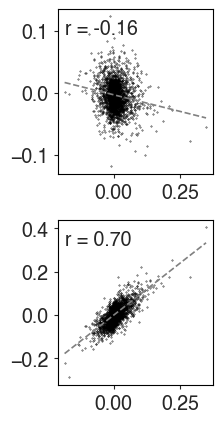

AURKB+ctrl
GEARS:
  R2_sklearn: 0.4339985619256679
  corr: 0.6849922391366755 corr^2: 0.46921436767747643
UniPert:
  R2_sklearn: -0.20310649244159484
  corr: 0.7809588302321523 corr^2: 0.6098966945175717


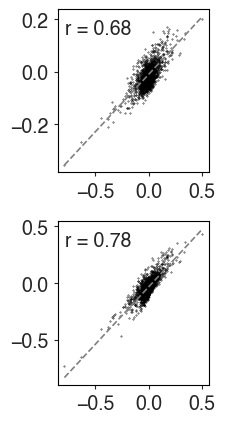

AURKA+ctrl
GEARS:
  R2_sklearn: 0.19920357648872622
  corr: 0.45892920910588564 corr^2: 0.2106160189705537
UniPert:
  R2_sklearn: -0.37584468897745404
  corr: 0.7332610059393497 corr^2: 0.537671702831187


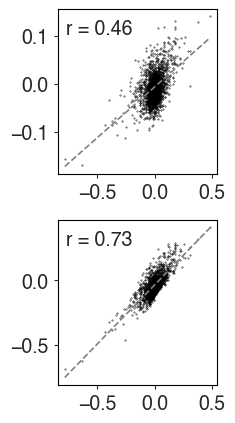

NR2C2+ctrl
GEARS:
  R2_sklearn: -0.5467040972666006
  corr: -0.0041264551144207014 corr^2: 1.7027631811328765e-05
UniPert:
  R2_sklearn: -0.5138962244004888
  corr: 0.12566435395879527 corr^2: 0.015791529855881385


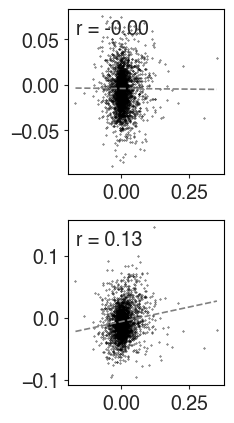

CEP55+ctrl
GEARS:
  R2_sklearn: 0.21128390856537316
  corr: 0.46982142154231976 corr^2: 0.22073216814004612
UniPert:
  R2_sklearn: 0.3229346917597108
  corr: 0.8322782761213402 corr^2: 0.6926871289035098


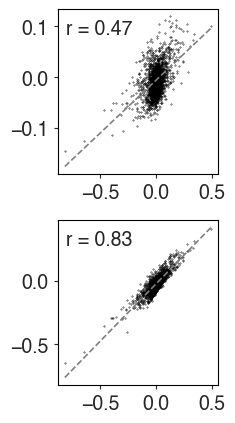

In [15]:
for i in test_pert_genes:
    query = i
    query_ = [q for q in query.split('+') if q != 'ctrl']

    pred1 = gears.predict([query_])['_'.join(query_)]
    pred2 = unipert.predict([query_])['_'.join(query_)]

    print(query)
    plot_perturbation_compare2(query, adata, pred1, pred2,
                              )